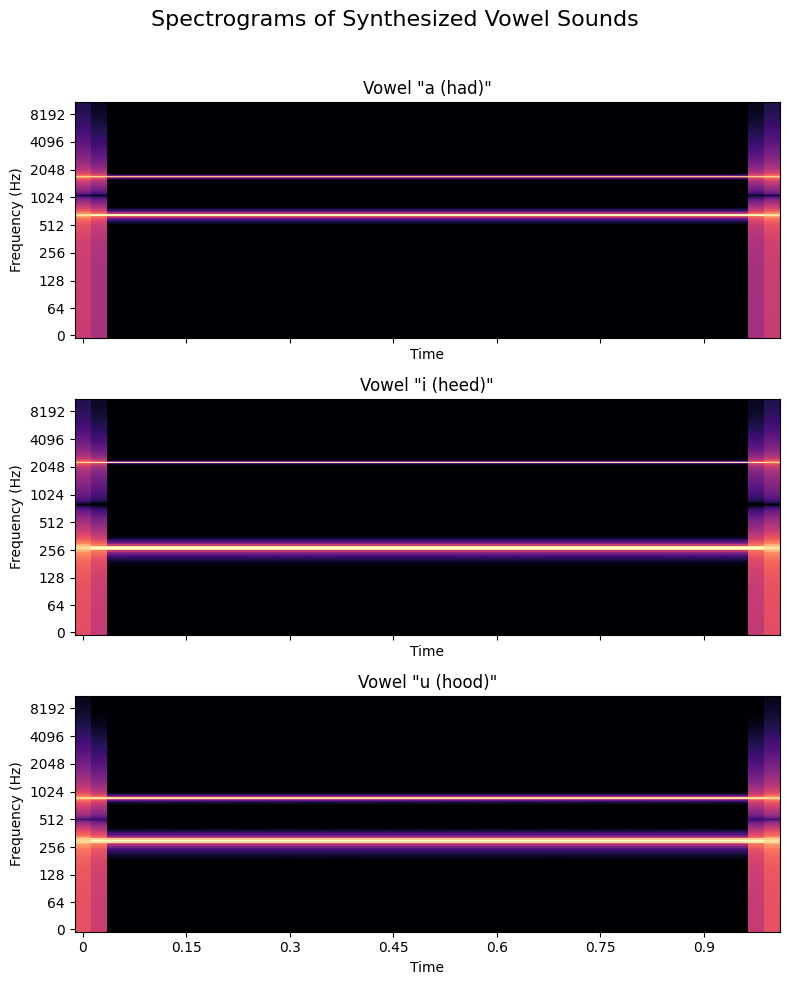

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

# --- Basic audio parameters ---
sr = 22050  # Sampling rate
duration = 1.0  # 1 second long
t = np.linspace(0, duration, int(sr * duration), endpoint=False)

# --- Vowel Formant Frequencies (approximate) ---
vowels = {
    'a (had)': {'f1': 660, 'f2': 1720},
    'i (heed)': {'f1': 270, 'f2': 2290},
    'u (hood)': {'f1': 300, 'f2': 870}
}

# --- Create and plot spectrograms for each vowel ---
fig, axs = plt.subplots(len(vowels), 1, figsize=(8, 10), sharex=True)
fig.suptitle('Spectrograms of Synthesized Vowel Sounds', fontsize=16)

for i, (vowel_name, freqs) in enumerate(vowels.items()):
    # Create the sound by adding two sine waves (formants)
    f1 = freqs['f1']
    f2 = freqs['f2']
    sound = np.sin(2 * np.pi * f1 * t) + np.sin(2 * np.pi * f2 * t)

    # Calculate and plot the spectrogram
    D = librosa.stft(sound)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log', ax=axs[i])

    axs[i].set_title(f'Vowel "{vowel_name}"')
    axs[i].set_ylabel('Frequency (Hz)')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()